Generando gráfica para análisis de mínimos locales...


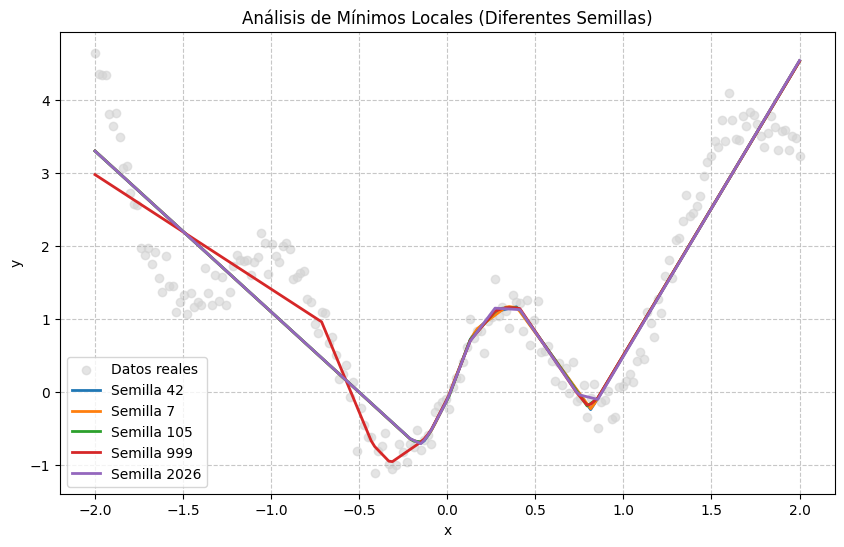

Generando gráfica para impacto de la tasa de aprendizaje...


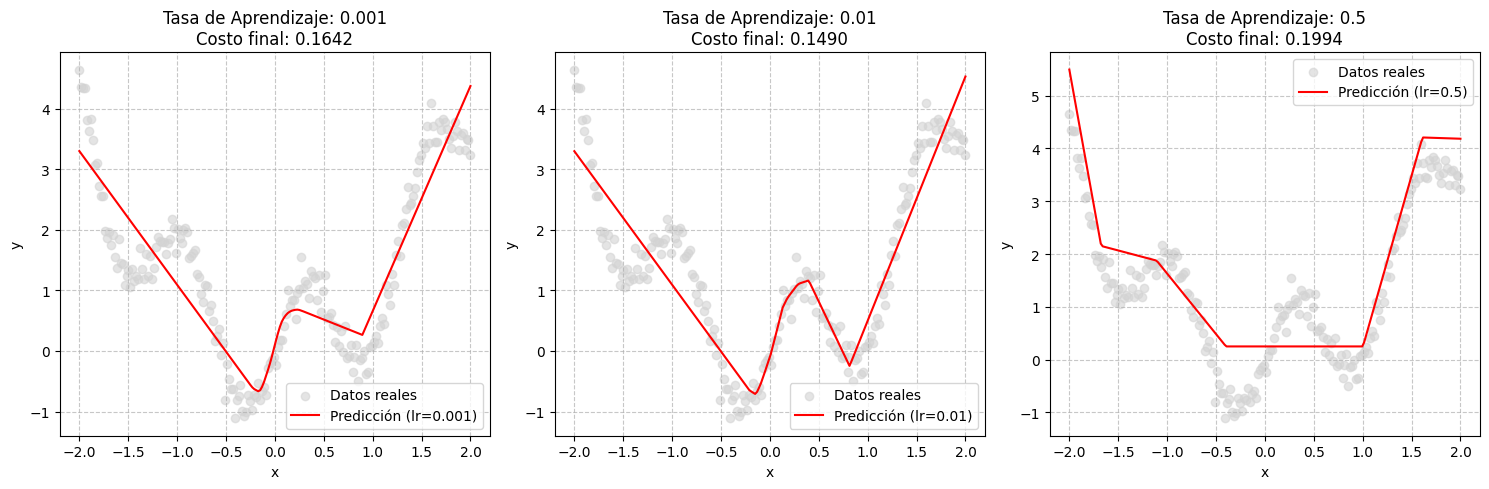

In [13]:
import numpy as np
import matplotlib.pyplot as plt


# 1. Generación de Datos
def generar_datos(n_samples=200, noise_std=0.2, seed=42):
    """
    Genera el conjunto de datos objetivo y = x^2 + sin(5x) + epsilon
    en el intervalo x in [-2, 2].
    """
    np.random.seed(seed)
    x = np.linspace(-2, 2, n_samples).reshape(-1, 1)
    epsilon = np.random.normal(0, noise_std, size=x.shape)
    y = x**2 + np.sin(5 * x) + epsilon
    return x, y


# 2. Programación del Algoritmo (Red Neuronal)
class RedNeuronalManual:
    def __init__(self, input_dim=1, hidden_dim=100, output_dim=1, seed=None):
        """
        Inicializa los pesos y sesgos de la red neuronal con una capa oculta.
        """
        if seed is not None:
            np.random.seed(seed)

        # Inicialización de He/Xavier básica para estabilizar el entrenamiento
        self.w1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2. / input_dim)
        self.b1 = np.zeros((1, hidden_dim))

        self.w2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2. / hidden_dim)
        self.b2 = np.zeros((1, output_dim))

    def relu(self, z):
        return np.maximum(0, z)

    def relu_derivada(self, z):
        return (z > 0).astype(float)

    def forward(self, x):
        """
        Paso hacia adelante (Forward Pass).
        """
        self.x = x
        self.z1 = np.dot(x, self.w1) + self.b1
        self.a1 = self.relu(self.z1)

        self.y_hat = np.dot(self.a1, self.w2) + self.b2
        return self.y_hat

    def backward(self, y, lr):
        """
        Paso hacia atrás con Gradient Clipping implementado.
        """
        n = y.shape[0]

        # 1. Cálculo de gradientes originales
        delta_out = (1 / n) * (self.y_hat - y)
        dw2 = np.dot(self.a1.T, delta_out)
        db2 = np.sum(delta_out, axis=0, keepdims=True)

        delta_hidden = np.dot(delta_out, self.w2.T) * self.relu_derivada(self.z1)
        dw1 = np.dot(self.x.T, delta_hidden)
        db1 = np.sum(delta_hidden, axis=0, keepdims=True)

        # 2. SOLUCIÓN: Gradient Clipping
        # Acotamos los gradientes a un rango seguro, por ejemplo [-1.0, 1.0]
        umbral = 1.0
        dw1 = np.clip(dw1, -umbral, umbral)
        db1 = np.clip(db1, -umbral, umbral)
        dw2 = np.clip(dw2, -umbral, umbral)
        db2 = np.clip(db2, -umbral, umbral)

        # 3. Actualización de pesos y sesgos
        self.w1 -= lr * dw1
        self.b1 -= lr * db1
        self.w2 -= lr * dw2
        self.b2 -= lr * db2

    def train(self, x, y, epochs, lr):
        """
        Bucle de entrenamiento.
        """
        historial_costo = []
        n = y.shape[0]
        for _ in range(epochs):
            y_hat = self.forward(x)
            costo = (1 / (2 * n)) * np.sum((y_hat - y)**2)
            historial_costo.append(costo)
            self.backward(y, lr)
        return historial_costo


# 3. Análisis de Mínimos Locales (5 Semillas)
def analizar_minimos_locales(x, y):
    semillas = [42, 7, 105, 999, 2026]
    epochs = 100000
    lr = 0.01
    H = 100

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='lightgray', label='Datos reales', alpha=0.6)

    for i, seed in enumerate(semillas):
        nn = RedNeuronalManual(hidden_dim=H, seed=seed)
        nn.train(x, y, epochs=epochs, lr=lr)
        y_pred = nn.forward(x)
        plt.plot(x, y_pred, label=f'Semilla {seed}', linewidth=2)

    plt.title("Análisis de Mínimos Locales (Diferentes Semillas)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()


# 4. Impacto de la Tasa de Aprendizaje
def analizar_tasa_aprendizaje(x, y):
    tasas = [0.001, 0.01, 0.5]
    epochs = 100000
    H = 100
    seed = 42

    plt.figure(figsize=(15, 5))

    for i, lr in enumerate(tasas):
        nn = RedNeuronalManual(hidden_dim=H, seed=seed)
        historial = nn.train(x, y, epochs=epochs, lr=lr)
        y_pred = nn.forward(x)

        # Gráfica de ajuste
        plt.subplot(1, 3, i+1)
        plt.scatter(x, y, color='lightgray', label='Datos reales', alpha=0.6)
        plt.plot(x, y_pred, color='red', label=f'Predicción (lr={lr})')
        plt.title(f'Tasa de Aprendizaje: {lr}\nCosto final: {historial[-1]:.4f}')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()


# Ejecución principal
if __name__ == "__main__":
    # Generar datos del problema
    X, Y = generar_datos()

    # Tarea 3: Ejecutar con distintas semillas
    print("Gráfica para análisis de mínimos locales")
    analizar_minimos_locales(X, Y)

    # Tarea 4: Ejecutar con distintas tasas de aprendizaje
    print("Gráfica para impacto de la tasa de aprendizaje")
    analizar_tasa_aprendizaje(X, Y)